# Сегментация пользователей EdTech-платформы

### Содержание
1. [Загрузка и первичный осмотр](#s1)
2. [Время событий: чем боты отличаются от учителей](#s2)
3. [Согласованность столбцов](#s3)
4. [Пропуски в `module`](#s4)
5. [Итог EDA: найденные аномалии](#s5)
6. [Очистка данных](#s6)
7. [Данные после очистки](#s7)
8. [Матрица «учитель - продуктовые метрики»](#s8)
9. [Подготовка признаков для моделирования](#s9)
10. [Кластеризация: K-Means и DBSCAN](#s10)
11. [Оценка качества кластеризации](#s11)
12. [Портреты сегментов](#s12)
13. [Бизнес-рекомендации](#s13)
14. [Дополнительно: классификатор и RFM-анализ](#s14)
15. [Итоги](#s15)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.decomposition import PCA
import seaborn as sns
from scipy import stats
from IPython.display import display

RAW_PATH = Path('data/teacher_activity_logs.csv')

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'grid.color': '#e6e6e3',
    'axes.titleweight': 'bold',
})
TEACHER_COLOR = '#2a78d6'   # учителя
BOT_COLOR = '#eb6834'       # боты

## <a id="s1"></a>1. Загрузка и первичный осмотр

In [2]:
raw = pd.read_csv(RAW_PATH)
print(f'Размер таблицы: {raw.shape[0]:,} строк × {raw.shape[1]} столбцов')
raw.head()

Размер таблицы: 214,959 строк × 7 столбцов


,user_id,timestamp,event_type,module,session_id,region,school_id
0,BOT001,2026-03-01 00:00:48,webinar_hosted,Вебинары,SBOT,Москва,1
1,BOT004,2026-03-01 00:01:44,webinar_started,Вебинары,SBOT,Москва,1
2,BOT014,2026-03-01 00:02:41,material_downloaded,Библиотека материалов,SBOT,Москва,1
3,BOT001,2026-03-01 00:03:38,webinar_hosted,Вебинары,SBOT,Москва,1
4,BOT002,2026-03-01 00:04:31,homework_assigned,Домашние задания,SBOT,Москва,1


In [3]:
types = pd.DataFrame({
    'тип': raw.dtypes,
    'уникальных': raw.nunique(),
    'пропусков': raw.isna().sum(),
})
display(types)

,тип,уникальных,пропусков
user_id,str,1515,0
timestamp,str,128604,0
event_type,str,9,0
module,str,5,12806
session_id,str,3971,0
region,str,8,0
school_id,int64,383,0


7 столбцов, пропуски есть только в `module` (6% строк). `timestamp` прочитан как строка - для анализа времени его нужно перевести в дату. Уникальных `user_id` 1 515, а по описанию учителей 1 500 - значит, в логе есть посторонние аккаунты.

### Дубликаты

In [4]:
KEY = ['user_id', 'timestamp', 'event_type']

n_full_dup = raw.duplicated().sum()
n_key_dup = raw.duplicated(KEY).sum()
print(f'Полных дубликатов строк: {n_full_dup}')
print(f'Почти-дубликатов (тот же пользователь, минута и событие, '
      f'но другой session_id или пропуск в module): {n_key_dup - n_full_dup}')

near = raw[raw.duplicated(KEY, keep=False) & ~raw.duplicated(keep=False)]
display(near.sort_values(KEY).head(8))

Полных дубликатов строк: 29
Почти-дубликатов (тот же пользователь, минута и событие, но другой session_id или пропуск в module): 52


,user_id,timestamp,event_type,module,session_id,region,school_id
35901,BOT007,2026-03-08 14:26:51,homework_assigned,Домашние задания,SBOT,Москва,1
35902,BOT007,2026-03-08 14:26:51,homework_assigned,NaN,SBOT,Москва,1
166570,BOT014,2026-04-04 22:16:09,webinar_started,NaN,SBOT,Москва,1
166571,BOT014,2026-04-04 22:16:09,webinar_started,Вебинары,SBOT,Москва,1
193185,T100007,2026-04-10 13:40:00,webinar_started,Вебинары,S27,Новосибирск,235
193187,T100007,2026-04-10 13:40:00,webinar_started,Вебинары,S17,Новосибирск,235
27633,T100036,2026-03-06 19:17:00,grade_entered,NaN,S436,Уфа,33
27635,T100036,2026-03-06 19:17:00,grade_entered,Оценки,S236,Уфа,33


Кроме полных дубликатов есть почти-дубли: одно и то же действие записано дважды в одну минуту, но с разным `session_id` или с пропущенным модулем. `drop_duplicates()` по всем столбцам их не ловит - удалять нужно по ключу `user_id + timestamp + event_type`.

### Категориальные признаки и форматы идентификаторов

In [5]:
for col in ['event_type', 'module', 'region']:
    display(raw[col].value_counts().rename('Событий').to_frame().T)
print('school_id: от', raw['school_id'].min(), 'до', raw['school_id'].max())
print('\nФормат всех user_id «BOT + 3 цифры» или «T10 + 4 цифры»:', raw['user_id'].str.fullmatch(r'BOT\d{3}|T10\d{4}').all())
print('Формат user_id «BOT + 3 цифры»:', raw['user_id'].str.fullmatch(r'BOT\d{3}').sum())
print('Формат user_id «T10 + 4 цифры»:', raw['user_id'].str.fullmatch(r'T10\d{4}').sum())
print('\nФормат всех session_id «SBOT» или «S + 2-4 цифры»:', raw['session_id'].str.fullmatch(r'SBOT|S\d{2,4}').all())
print('Формат session_id «SBOT»:', raw['session_id'].str.fullmatch(r'SBOT').sum())
print('Формат session_id «S + 2-4 цифры»:', raw['session_id'].str.fullmatch(r'S\d{2,4}').sum())
print('\nСессии SBOT ровно у BOT-аккаунтов:',
      (raw['session_id'].eq('SBOT') == raw['user_id'].str.startswith('BOT')).all())

event_type,homework_assigned,homework_checked,schedule_viewed,material_viewed,material_downloaded,grade_viewed,grade_entered,webinar_started,webinar_hosted
Событий,34480,34469,29117,22233,22215,21169,20903,15304,15069


module,Домашние задания,Библиотека материалов,Оценки,Вебинары,Расписание
Событий,64787,41824,39577,28620,27345


region,Москва,Санкт-Петербург,Новосибирск,Казань,Пермь,Краснодар,Екатеринбург,Уфа
Событий,110288,16783,16065,15244,15147,14524,13984,12924


school_id: от 1 до 399

Формат всех user_id «BOT + 3 цифры» или «T10 + 4 цифры»: True
Формат user_id «BOT + 3 цифры»: 94291
Формат user_id «T10 + 4 цифры»: 120668



Формат всех session_id «SBOT» или «S + 2-4 цифры»: True
Формат session_id «SBOT»: 94291
Формат session_id «S + 2-4 цифры»: 120668

Сессии SBOT ровно у BOT-аккаунтов: True


Аккаунтов 2 вида: 15 `BOT…` (94 291 событие, 44% лога) и 1 500 учителей `T10…`. У всех ботов сессия `SBOT`.

## <a id="s2"></a>2. Время событий: чем боты отличаются от учителей

Проверяем, что `BOT…` - действительно автоматическая активность, а не просто аккаунты с необычным именем.

In [6]:
eda = raw.assign(
    ts=pd.to_datetime(raw['timestamp']),
    is_bot=raw['user_id'].str.startswith('BOT'),
)
eda['группа'] = eda['is_bot'].map({False: 'Учителя (T…)', True: 'Боты (BOT…)'})

print('Период лога:', eda['ts'].min(), '-', eda['ts'].max(),
      f"({eda['ts'].dt.normalize().nunique()} дней)")

grp = eda.groupby('группа')
bot_vs_teacher = pd.DataFrame({
    'аккаунтов': grp['user_id'].nunique(),
    'событий': grp.size(),
    'событий на аккаунт, медиана': grp['user_id'].apply(lambda s: s.value_counts().median()),
    'событий на аккаунт, макс.': grp['user_id'].apply(lambda s: s.value_counts().max()),
    'часы активности': grp['ts'].apply(lambda s: f'{s.dt.hour.min()}:00-{s.dt.hour.max()}:59'),
    'доля событий с секундами ≠ 0': grp['ts'].apply(lambda s: f'{(s.dt.second != 0).mean():.1%}'),
    'регионов': grp['region'].nunique(),
    'школ': grp['school_id'].nunique(),
}).T
display(bot_vs_teacher)

Период лога: 2026-03-01 00:00:48 - 2026-04-14 23:59:33 (45 дней)


группа,Боты (BOT…),Учителя (T…)
аккаунтов,15,1500
событий,94291,120668
"событий на аккаунт, медиана",6288.0,47.0
"событий на аккаунт, макс.",6687,243
часы активности,0:00-23:59,7:00-20:59
доля событий с секундами ≠ 0,98.3%,0.0%
регионов,1,8
школ,1,383


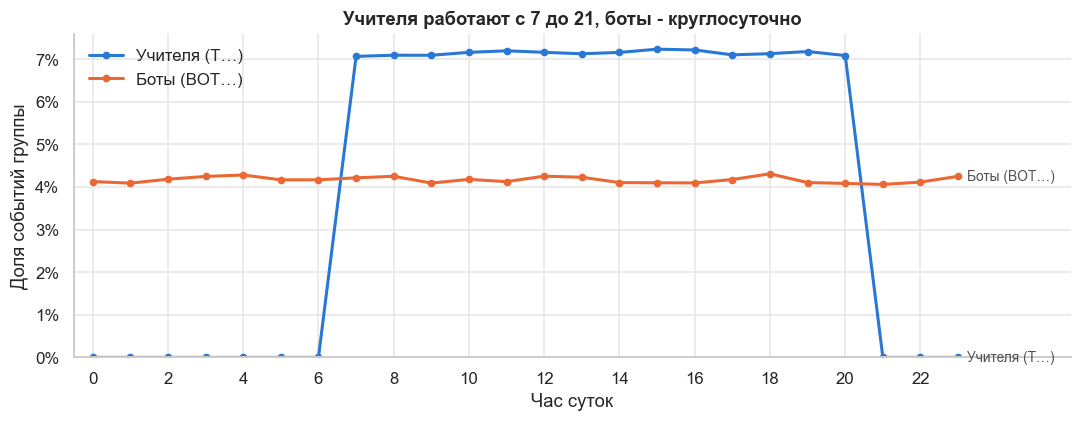

In [7]:
hour_share = (eda.groupby(['группа', eda['ts'].dt.hour]).size()
                 .groupby(level=0).transform(lambda s: s / s.sum() * 100)
                 .unstack(0)
                 .reindex(range(24))
                 .fillna(0))

fig, ax = plt.subplots(figsize=(10, 4))
for name, color in [('Учителя (T…)', TEACHER_COLOR), ('Боты (BOT…)', BOT_COLOR)]:
    s = hour_share[name]
    ax.plot(s.index, s.values, color=color, linewidth=2, marker='o', markersize=4, label=name)
    ax.annotate(name, (s.index[-1], s.values[-1]), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=9, color='#52514e')
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 26)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel('Час суток')
ax.set_ylabel('Доля событий группы')
ax.set_title('Учителя работают с 7 до 21, боты - круглосуточно')
ax.legend(loc='upper left', frameon=False)
plt.tight_layout()
plt.show()

**Вывод:**  `BOT…` — автоматическая активность, это видно не только по имени:
- активность круглосуточная и равномерная, у учителей - только 7:00-20:59;
- время с точностью до секунды, а у учителей секунды всегда `:00`;
- у каждого бота около 6 300 событий, у самого активного учителя - 243;
- все боты - в одной «школе» 1 в Москве, сессия у всех одна (`SBOT`).

Ботов удаляем целиком.

## <a id="s3"></a>3. Согласованность столбцов

In [8]:
ct = pd.crosstab(eda['event_type'], eda['module'].fillna('— пропуск —'))
display(ct)
one_to_one = (ct.drop(columns='— пропуск —') > 0).sum(axis=1).eq(1).all()
print('Каждому event_type соответствует ровно один модуль:', one_to_one)

module,Библиотека материалов,Вебинары,Домашние задания,Оценки,Расписание,— пропуск —
event_type,,,,,,
grade_entered,0,0,0,19654,0,1249
grade_viewed,0,0,0,19923,0,1246
homework_assigned,0,0,32397,0,0,2083
homework_checked,0,0,32390,0,0,2079
material_downloaded,20932,0,0,0,0,1283
material_viewed,20892,0,0,0,0,1341
schedule_viewed,0,0,0,0,27345,1772
webinar_hosted,0,14187,0,0,0,882
webinar_started,0,14433,0,0,0,871


Каждому event_type соответствует ровно один модуль: True


In [9]:
school_regions = eda.groupby('school_id')['region'].nunique()
print(f'School_id, встречающихся в нескольких регионах: {(school_regions > 1).sum()} из {len(school_regions)}')
print('У каждого учителя один регион:', eda.groupby('user_id')['region'].nunique().eq(1).all())
print('У каждого учителя одна школа:', eda.groupby('user_id')['school_id'].nunique().eq(1).all())

School_id, встречающихся в нескольких регионах: 350 из 383
У каждого учителя один регион: True
У каждого учителя одна школа: True


In [10]:
t = eda[~eda['is_bot']]
sess_users = t.groupby('session_id')['user_id'].nunique()
print(f'Одинаковый session_id у двух и более учителей: {(sess_users > 1).sum()} из {len(sess_users)}')
print('Session_id на одного учителя за 45 дней:')
display(t.groupby('user_id')['session_id'].nunique().value_counts().sort_index()
          .rename('учителей').to_frame().T)

Одинаковый session_id у двух и более учителей: 1973 из 3970
Session_id на одного учителя за 45 дней:


session_id,1,2,3,4
учителей,1,5,44,1450


**Вывод:**
- `event_type → module` - строго один к одному. Значит, пропуски в `module` можно восстановить без потерь.
- `school_id` **не уникален**: один номер встречается в разных регионах. Школу однозначно задаёт только пара `region + school_id`. В анализе школа не используется: это не поведенческий признак.
- `session_id` **не уникален** между учителями, и у учителя всего до 4 «сессий» за 45 дней. Это не сессии входа: считать по нему частоту входов нельзя.
- В логе нет события «вход», поэтому частоту использования считаем по **активным дням**.

## <a id="s4"></a>4. Пропуски в `module`

In [11]:
na_share = pd.DataFrame({
    'боты': eda[eda['is_bot']].groupby('event_type')['module'].apply(lambda s: s.isna().mean()),
    'учителя': eda[~eda['is_bot']].groupby('event_type')['module'].apply(lambda s: s.isna().mean()),
})
display((na_share * 100).round(1).astype(str) + '%')
print(f"Пропусков у учителей: {eda.loc[~eda['is_bot'], 'module'].isna().sum()} "
      f"({eda.loc[~eda['is_bot'], 'module'].isna().mean():.1%} их событий)")

na_by_user = eda[~eda['is_bot']].groupby('user_id')['module'].apply(lambda s: s.isna().mean())
print(f'Учителей хотя бы с одним пропуском: {(na_by_user > 0).sum()} из {len(na_by_user)}')

,боты,учителя
event_type,,
grade_entered,6.2%,5.8%
grade_viewed,5.8%,5.9%
homework_assigned,6.4%,5.9%
homework_checked,5.9%,6.1%
material_downloaded,5.9%,5.7%
material_viewed,6.5%,5.7%
schedule_viewed,6.2%,6.0%
webinar_hosted,5.8%,6.0%
webinar_started,5.7%,5.7%


Пропусков у учителей: 7102 (5.9% их событий)


Учителей хотя бы с одним пропуском: 1306 из 1500


Пропуски в `module` равномерно распределены по всем типам событий и почти у всех учителей. Это техническая потеря поля, а не особенность поведения. Удалять такие строки нельзя: пропали бы ~6% действий учителей. Модуль восстанавливаем по `event_type`.

## <a id="s5"></a>5. Итог EDA: найденные аномалии

| Аномалия | Объём | Решение |
|---|---|---|
| Боты `BOT…` / `SBOT` | 15 аккаунтов, 94 283 события | удалить |
| Полные дубликаты | 29 строк | удалить |
| Почти-дубли (то же событие в ту же минуту) | 52 строки, из них 50 у учителей | удалить по `user_id + timestamp + event_type` |
| Пропуски в `module` | 7 102 строки учителей | восстановить по `event_type` |
| `session_id` не уникален и не отражает входы | все строки | не использовать для частоты входов |
| `school_id` не уникален между регионами | 350 школ | в анализе не используем |

## <a id="s6"></a>6. Очистка данных

In [12]:
df = raw.copy()
n_before = len(df)
df = df[df['session_id'] != 'SBOT']
df = df[~df['user_id'].str.fullmatch(r'BOT\d{3}')]
print(f'Удалено бот-сессий: {n_before - len(df)}; осталось строк: {len(df)}')

Удалено бот-сессий: 94291; осталось строк: 120668


Восстанавливаем пропуски в `module` по `event_type`

In [13]:
ev2mod = df.dropna(subset=['module']).groupby('event_type')['module'].agg(lambda s: s.mode()[0])
n_na = df['module'].isna().sum()
df['module'] = df['module'].fillna(df['event_type'].map(ev2mod))
print(f'Заполнено пропусков: {n_na}; осталось: {df["module"].isna().sum()}')

Заполнено пропусков: 7102; осталось: 0


In [14]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Удалено дубликатов: {n_before - len(df)}; осталось строк: {len(df)}')

Удалено дубликатов: 25; осталось строк: 120643


In [15]:
n_before = len(df)
df = df.drop_duplicates(subset=KEY).reset_index(drop=True)
print(f'Удалено почти-дублей: {n_before - len(df)}; осталось строк: {len(df)}')

Удалено почти-дублей: 46; осталось строк: 120597


Приведение типов

In [16]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

### Учителя с малой активностью и неполным периодом наблюдения

In [17]:
period_start = df['timestamp'].min().normalize()
period_end = df['timestamp'].max().normalize()

teachers = df.groupby('user_id').agg(
    events=('event_type', 'size'),
    active_days=('timestamp', lambda s: s.dt.normalize().nunique()),
    first_seen=('timestamp', 'min'),
    last_seen=('timestamp', 'max'),
)
teachers['days_in_log'] = (period_end - teachers['first_seen'].dt.normalize()).dt.days + 1
teachers['low_activity'] = (teachers['events'] < 5) | (teachers['active_days'] < 3)
teachers['new_user'] = teachers['first_seen'] >= period_start + pd.Timedelta(days=30)
teachers['gone'] = teachers['last_seen'] < period_end - pd.Timedelta(days=30)

print(f'Учителей: {len(teachers)}')
print(f"Мало активности (< 5 событий или < 3 активных дней): {teachers['low_activity'].sum()}")
print(f"Пришли в последние 15 дней: {teachers['new_user'].sum()}")
print(f"Не заходили последние 30 дней: {teachers['gone'].sum()}")
display(teachers.sort_values('events').head(10))

Учителей: 1500
Мало активности (< 5 событий или < 3 активных дней): 17
Пришли в последние 15 дней: 4
Не заходили последние 30 дней: 2


,events,active_days,first_seen,last_seen,days_in_log,low_activity,new_user,gone
user_id,,,,,,,,
T100251,1,1,2026-04-11 09:47:00,2026-04-11 09:47:00,4,True,True,False
T100235,3,1,2026-03-09 09:26:00,2026-03-09 16:19:00,37,True,False,True
T100005,3,2,2026-03-10 07:22:00,2026-04-09 16:47:00,36,True,False,False
T100041,4,2,2026-03-02 11:06:00,2026-03-15 20:48:00,44,True,False,False
T100612,4,2,2026-03-31 09:12:00,2026-04-05 10:42:00,15,True,True,False
T100385,4,2,2026-03-07 08:13:00,2026-03-21 08:41:00,39,True,False,False
T101083,4,3,2026-03-21 19:39:00,2026-04-05 19:42:00,25,True,False,False
T100645,4,3,2026-03-01 07:11:00,2026-03-15 15:15:00,45,True,False,False
T101056,4,2,2026-03-09 17:11:00,2026-04-03 20:08:00,37,True,False,False


Эти учителя - не мусор, а реальные, но почти неактивные пользователи. Удалять их не стоит. Но в кластеризации у них будут крайние значения, и они утянут центры K-Means и попадут в шум DBSCAN. Поэтому:
- учителей с `low_activity` исключаем из кластеризации и описываем отдельным сегментом «Спящие»;
- частоту считаем на день присутствия в логе (`days_in_log`), чтобы новички не выглядели неактивными.

## <a id="s7"></a>7. Данные после очистки

In [18]:
print(f'Строк: {len(raw)} → {len(df)}')
print(f"Учителей: {df['user_id'].nunique()}")
print(f"Период: {df['timestamp'].min():%d.%m.%Y} - {df['timestamp'].max():%d.%m.%Y}")
print(f'Пропусков: {df.isna().sum().sum()}')

Строк: 214959 → 120597
Учителей: 1500
Период: 01.03.2026 - 14.04.2026
Пропусков: 0


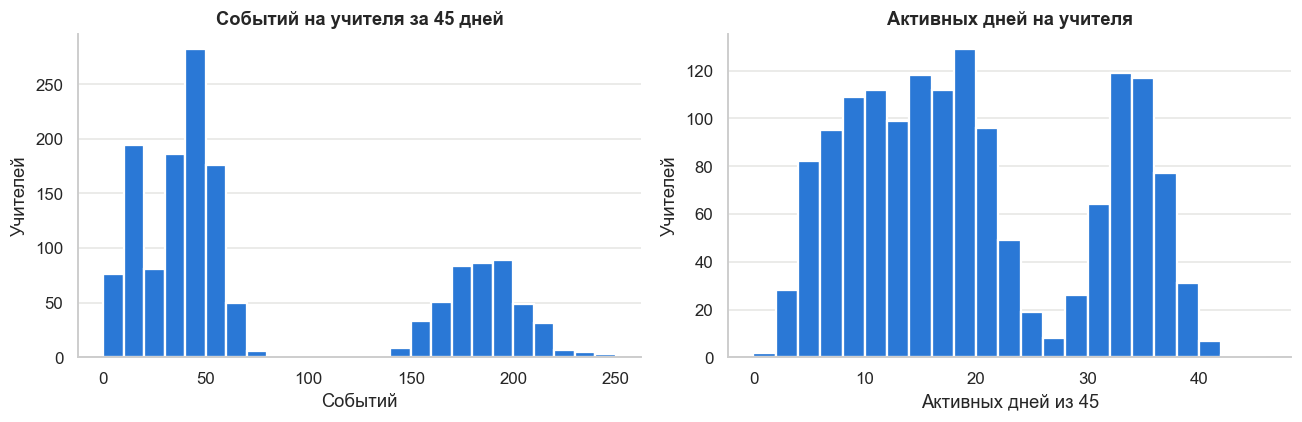

Учителей с 80-120 событиями: 0


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(teachers['events'], bins=range(0, 260, 10), color=TEACHER_COLOR,
             edgecolor='white', linewidth=1.5)
axes[0].set_title('Событий на учителя за 45 дней')
axes[0].set_xlabel('Событий')
axes[0].set_ylabel('Учителей')

axes[1].hist(teachers['active_days'], bins=range(0, 47, 2), color=TEACHER_COLOR,
             edgecolor='white', linewidth=1.5)
axes[1].set_title('Активных дней на учителя')
axes[1].set_xlabel('Активных дней из 45')
axes[1].set_ylabel('Учителей')

for ax in axes:
    ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

print(f"Учителей с 80-120 событиями: {teachers['events'].between(80, 120).sum()}")

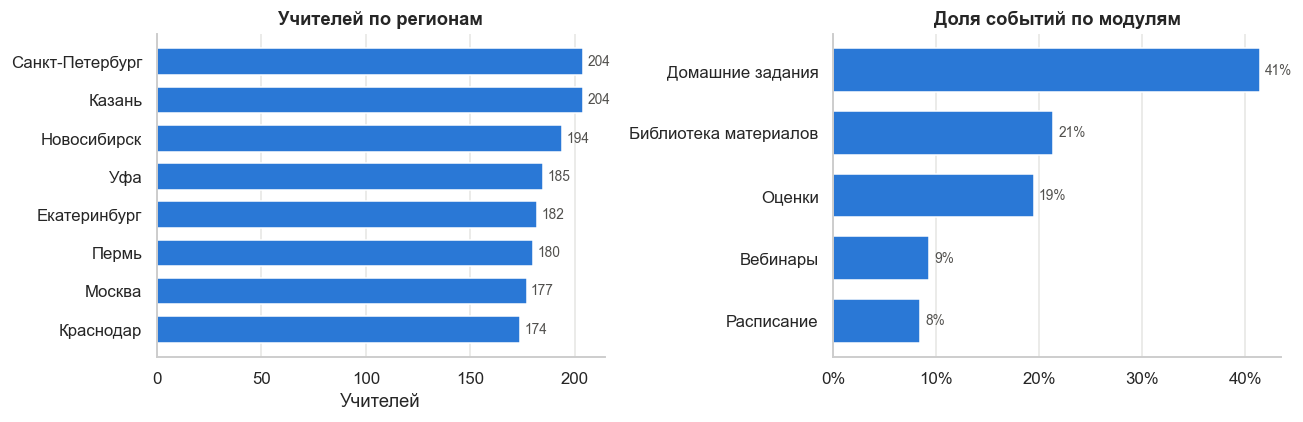

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

reg = df.groupby('region')['user_id'].nunique().sort_values()
axes[0].barh(reg.index, reg.values, color=TEACHER_COLOR, height=0.7)
for y, v in enumerate(reg.values):
    axes[0].text(v + 2, y, str(v), va='center', fontsize=9, color='#52514e')
axes[0].set_title('Учителей по регионам')
axes[0].set_xlabel('Учителей')
axes[0].grid(axis='y', visible=False)

mod = (df['module'].value_counts(normalize=True) * 100).sort_values()
axes[1].barh(mod.index, mod.values, color=TEACHER_COLOR, height=0.7)
for y, v in enumerate(mod.values):
    axes[1].text(v + 0.5, y, f'{v:.0f}%', va='center', fontsize=9, color='#52514e')
axes[1].set_title('Доля событий по модулям')
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].grid(axis='y', visible=False)

plt.tight_layout()
plt.show()

**Выводы после очистки:**
- Осталось 120 597 событий 1 500 учителей за 45 дней, пропусков нет.
- Без ботов регионы почти равны: 174-204 учителя.
- Распределение числа событий **двугорбое**: около 1 050 учителей делают до 80 действий за 45 дней, около 450 - 140-250, а с 80 до 120 событиями нет ни одного учителя. Это первый признак устойчивых поведенческих сегментов.
- Основная нагрузка - «Домашние задания» (41% событий).
- Число активных дней тоже делится на две группы: примерно до 25 дней и 28-42 дня из 45. Регулярность использования станет одним из ключевых признаков.

## <a id="s8"></a>8. Матрица «учитель - продуктовые метрики»

Метрики считаем для **1 483 учителей**: 17 «спящих» (`low_activity`, меньше 5 событий или меньше 3 активных дней) исключены, их опишем отдельным сегментом. В логе нет события «вход», поэтому **заход на платформу = активный день** (день, в который у учителя есть хотя бы одно событие).

Метрики разбиты на 4 группы. Каждая группа отвечает на свой продуктовый вопрос.

### 1. Частота: как часто учитель пользуется платформой

| Метрика | Как считается | Что показывает |
|---|---|---|
| `active_days` | число дней с хотя бы одним событием за 45 дней | сколько дней учитель заходил на платформу; основа продуктовой метрики «активные дни в месяц» |
| `active_days_share` | `active_days / days_in_log` | доля дней, в которые учитель был активен, считая от его первого появления в логе; уравнивает новичков с теми, кто был в логе все 45 дней |
| `events_per_day` | `events / active_days` | интенсивность одного визита: зашёл «на минуту» (1-2 действия) или работал долго (5+ действий) |

Общее число событий в матрицу не берём: оно почти полностью равно `active_days × events_per_day` и удвоило бы вес частоты.

### 2. Регулярность: стабильно или рывками

| Метрика | Как считается | Что показывает |
|---|---|---|
| `active_weeks_share` | число недель с активностью / число недель в логе (от недели первого появления учителя до конца периода; неделя = 7 дней от 01.03) | заходит каждую неделю или пропадает на недели; связана с удержанием |
| `median_gap` | медиана дней между соседними активными днями | ритм использования: 1 - ежедневная привычка, 7 - раз в неделю |
| `gap_cv` | стандартное отклонение интервалов / их среднее | ровность ритма: около 0 - заходит через одинаковые промежутки, больше 1 - активность рывками |
| `recency` | дней от последнего активного дня до конца периода (14.04) | давность последнего визита; большое значение - риск оттока |

### 3. Структура использования: какими разделами пользуется

| Метрика | Как считается | Что показывает |
|---|---|---|
| `share_homework` | доля событий в «Домашних заданиях» | насколько платформа для учителя - инструмент выдачи и проверки ДЗ |
| `share_library` | доля событий в «Библиотеке материалов» | использование платформы как цифровой библиотеки для подготовки уроков |
| `share_grades` | доля событий в «Оценках» | работа с журналом и оценками |
| `share_webinars` | доля событий в «Вебинарах» | работа с интерактивными инструментами: вебинары и трансляции |
| `share_schedule` | доля событий в «Расписании» | использование расписания |
| `n_modules` | сколько из 5 модулей использовал учитель | широта сценария: узкий (1-2 модуля) или вся платформа |

Доли в сумме дают 1 и описывают **профиль использования** независимо от того, насколько учитель активен. Именно они отличают три типа учителей из описания проекта: «домашка каждый день», «библиотека для очных уроков», «вебинары и интерактив».

### 4. Глубина работы с ключевыми модулями

| Метрика | Как считается | Что показывает |
|---|---|---|
| `homework_days_share` | доля активных дней, в которые была работа с ДЗ | ДЗ как ежедневная привычка: 1 - каждый визит связан с домашними заданиями |
| `webinar_days` | число дней с событиями в «Вебинарах» | регулярность вебинаров: разовый эксперимент или постоянный формат работы |
| `download_ratio` | `(material_downloaded + 1) / (material_viewed + 1)` | больше 1 - учитель скачивает материалы (готовится к очным урокам), меньше 1 - смотрит онлайн; +1 сглаживает отношение при малом числе событий |

Пары событий внутри модуля (`homework_assigned` / `homework_checked`, `grade_entered` / `grade_viewed`, `webinar_started` / `webinar_hosted`) отдельными признаками не берём: они не добавляют информации.

### Не входят в матрицу
- `region`, `school_id` - не поведение; регион используем при описании готовых сегментов.
- `session_id` - не отражает входы.

In [21]:
d = df.copy()
d['date'] = d['timestamp'].dt.normalize()
d['week'] = (d['date'] - period_start).dt.days // 7

base = teachers[~teachers['low_activity']]
m = pd.DataFrame(index=base.index)

# 1. Частота
m['active_days'] = base['active_days']
m['active_days_share'] = base['active_days'] / base['days_in_log']
m['events_per_day'] = base['events'] / base['active_days']

# 2. Регулярность
first_week = (base['first_seen'].dt.normalize() - period_start).dt.days // 7
last_week = (period_end - period_start).days // 7
weeks_in_log = last_week - first_week + 1
m['active_weeks_share'] = d.groupby('user_id')['week'].nunique().reindex(m.index) / weeks_in_log

days = d[['user_id', 'date']].drop_duplicates().sort_values(['user_id', 'date'])
days['gap'] = days.groupby('user_id')['date'].diff().dt.days
gap = days.groupby('user_id')['gap']
m['median_gap'] = gap.median().reindex(m.index)
m['gap_cv'] = (gap.std() / gap.mean()).reindex(m.index).fillna(0)
m['recency'] = (period_end - base['last_seen'].dt.normalize()).dt.days

# 3. Структура использования
module_names = {'Домашние задания': 'homework', 'Библиотека материалов': 'library',
                'Оценки': 'grades', 'Вебинары': 'webinars', 'Расписание': 'schedule'}
share = pd.crosstab(d['user_id'], d['module'].map(module_names), normalize='index')
m = m.join(share.add_prefix('share_'))
m['n_modules'] = d.groupby('user_id')['module'].nunique()

# 4. Глубина
module_days = d.groupby(['user_id', 'module'])['date'].nunique().unstack(fill_value=0)
m['homework_days_share'] = module_days['Домашние задания'].reindex(m.index) / m['active_days']
m['webinar_days'] = module_days['Вебинары'].reindex(m.index)
ev = pd.crosstab(d['user_id'], d['event_type']).reindex(m.index)
m['download_ratio'] = (ev['material_downloaded'] + 1) / (ev['material_viewed'] + 1)

display(m.head())
m = m.fillna(0)
display(m.describe().T)

,active_days,active_days_share,events_per_day,active_weeks_share,median_gap,gap_cv,recency,share_grades,share_homework,share_library,share_schedule,share_webinars,n_modules,homework_days_share,webinar_days,download_ratio
user_id,,,,,,,,,,,,,,,,
T100000,11,0.255814,3.454545,0.857143,2.5,0.731423,6,0.078947,0.078947,0.078947,0.236842,0.526316,5,0.181818,10,1.500000
T100001,18,0.418605,2.222222,0.857143,1.0,0.780995,6,0.050000,0.125000,0.675000,0.100000,0.050000,5,0.166667,2,0.812500
T100002,8,0.177778,2.000000,0.714286,5.0,0.884419,0,0.125000,0.125000,0.312500,0.312500,0.125000,5,0.250000,1,1.333333
T100003,9,0.230769,3.666667,0.857143,3.5,0.833314,9,0.090909,0.060606,0.060606,0.121212,0.666667,5,0.222222,9,3.000000
T100004,31,0.688889,5.000000,1.000000,1.0,0.613332,0,0.212903,0.600000,0.083871,0.032258,0.070968,5,1.000000,10,0.666667


,count,mean,std,min,25%,50%,75%,max
active_days,1483.0,19.566419,10.519701,3.000000,11.000000,18.000000,31.000000,42.000000
active_days_share,1483.0,0.448561,0.228444,0.071429,0.255814,0.400000,0.688889,0.933333
events_per_day,1483.0,3.532274,1.458176,1.166667,2.315789,2.789474,5.202941,6.620690
active_weeks_share,1483.0,0.895652,0.152671,0.250000,0.857143,1.000000,1.000000,1.000000
median_gap,1483.0,2.419757,1.993656,1.000000,1.000000,2.000000,3.000000,20.000000
gap_cv,1483.0,0.671348,0.219970,0.000000,0.514259,0.650356,0.797354,1.619048
recency,1483.0,2.229265,3.569821,0.000000,0.000000,1.000000,3.000000,32.000000
share_grades,1483.0,0.144005,0.101775,0.000000,0.055556,0.117647,0.235294,0.625000
share_homework,1483.0,0.256604,0.206249,0.000000,0.093023,0.150943,0.514970,0.652695
share_library,1483.0,0.333821,0.256440,0.000000,0.102041,0.210526,0.609756,0.916667


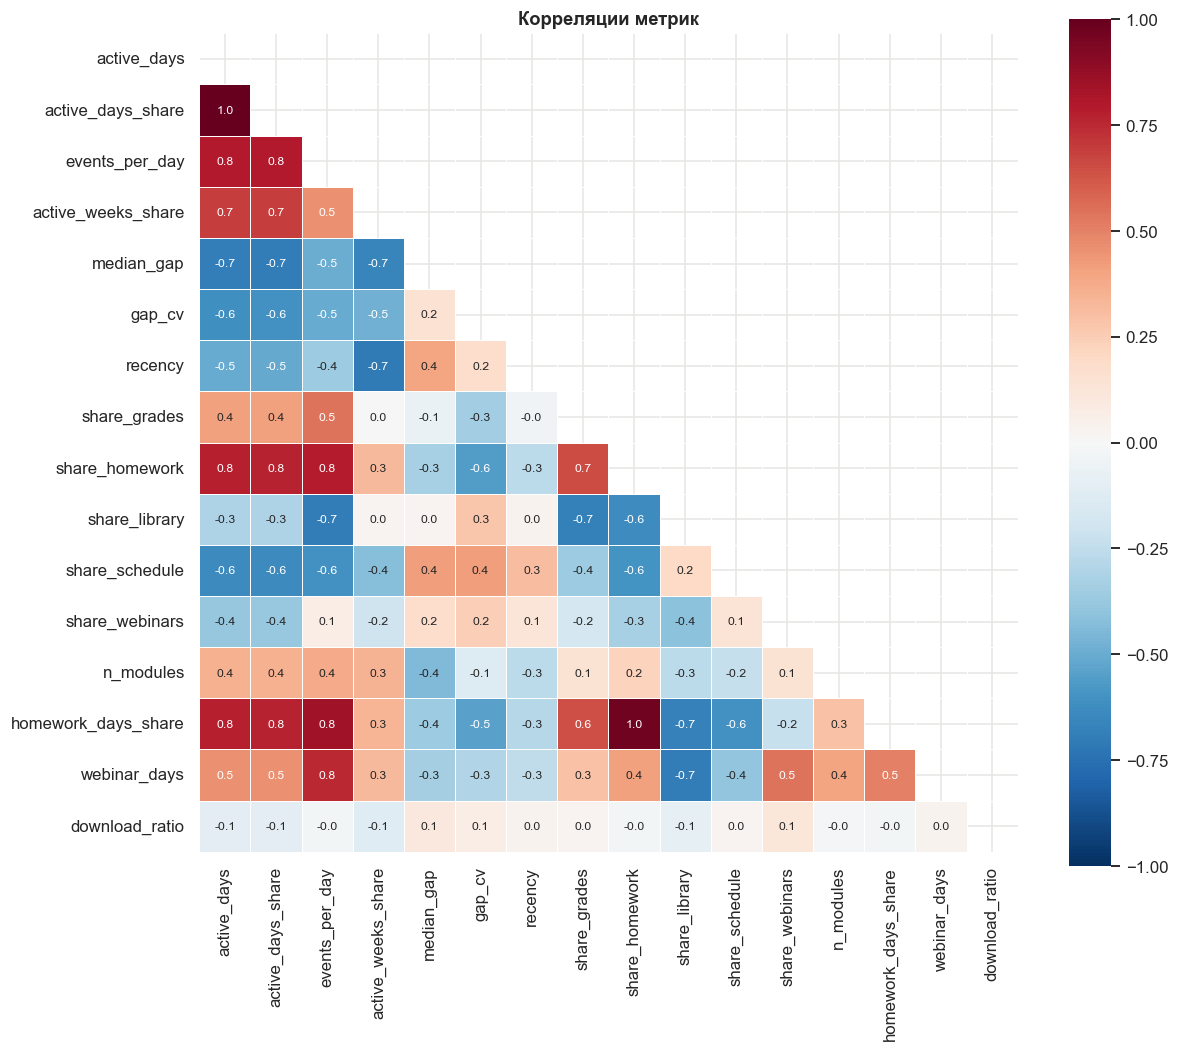

,,r
active_days,active_days_share,0.996613
share_homework,homework_days_share,0.974011


In [22]:
corr = m.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.1f', annot_kws={'size': 8}, square=True, linewidths=0.5)
plt.title('Корреляции метрик')
plt.show()

# пары с |r| > 0.9 - кандидаты на удаление
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
display(pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False).rename('r').to_frame())

**Вывод по корреляциям:**
- Две пары метрик - дубли (|r| > 0.9): `active_days` и `active_days_share` (r = 1.00), `share_homework` и `homework_days_share` (r = 0.97). Из каждой пары в модель пойдёт одна метрика, иначе одно и то же свойство будет учтено дважды.
- Сильные, но допустимые связи (0.7-0.85): активная работа с ДЗ связана с большим числом действий за визит, а «библиотечный» сценарий - с короткими визитами. Это намёк на будущие сегменты.
- `download_ratio` почти ни с чем не связан: это независимая характеристика поведения.

## <a id="s9"></a>9. Подготовка признаков для моделирования

План:
1. **Отбор признаков:** убираем дубли и признаки, которые почти не различают учителей.
2. **Логарифмирование** сильно скошенных признаков (`np.log1p`): иначе несколько учителей с крайними значениями растянут шкалу, K-Means будет подстраиваться под них, а DBSCAN отправит их в шум.
3. **Стандартизация** (`StandardScaler`): каждый признак приводим к среднему 0 и стандартному отклонению 1, чтобы все признаки имели одинаковый вес.

### 9.1. Отбор признаков

In [23]:
DROP = {
    'active_days': 'дубль active_days_share (r = 1.00)',
    'homework_days_share': 'дубль share_homework (r = 0.97)',
    'n_modules': 'почти не различает учителей',
    'active_weeks_share': 'почти не различает учителей',
}
LOG_COLS = ['median_gap', 'recency', 'download_ratio']

mode_share = pd.Series({c: (m[c] == m[c].mode()[0]).mean() for c in m.columns})
decision = pd.Series('стандартизация', index=m.columns)
decision[LOG_COLS] = 'log1p + стандартизация'
for col, reason in DROP.items():
    decision[col] = 'исключить: ' + reason

feature_review = pd.DataFrame({
    'асимметрия': m.skew().round(2),
    'доля самого частого значения': mode_share.map('{:.0%}'.format),
    'решение': decision,
})
display(feature_review)

features = [c for c in m.columns if c not in DROP]
print(f'Признаков в модели: {len(features)} из {m.shape[1]}')

,асимметрия,доля самого частого значения,решение
active_days,0.34,5%,исключить: дубль active_days_share (r = 1.00)
active_days_share,0.33,4%,стандартизация
events_per_day,0.40,4%,стандартизация
active_weeks_share,-1.50,59%,исключить: почти не различает учителей
median_gap,2.92,37%,log1p + стандартизация
gap_cv,0.71,0%,стандартизация
recency,2.82,41%,log1p + стандартизация
share_grades,0.38,7%,стандартизация
share_homework,0.60,3%,стандартизация
share_library,0.39,2%,стандартизация


Признаков в модели: 12 из 16


### 9.2. Логарифмирование и стандартизация

In [24]:
X_raw = m[features].copy()
X_raw[LOG_COLS] = np.log1p(X_raw[LOG_COLS])

scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_raw), index=X_raw.index, columns=features)

print('Проверка стандартизации (у каждого признака среднее 0, стандартное отклонение 1):')
display(X.describe().T[['mean', 'std', 'min', 'max']].round(2))

Проверка стандартизации (у каждого признака среднее 0, стандартное отклонение 1):


,mean,std,min,max
active_days_share,-0.0,1.0,-1.65,2.12
events_per_day,-0.0,1.0,-1.62,2.12
median_gap,0.0,1.0,-0.97,4.41
gap_cv,-0.0,1.0,-3.05,4.31
recency,-0.0,1.0,-0.96,3.32
share_grades,-0.0,1.0,-1.42,4.73
share_homework,0.0,1.0,-1.24,1.92
share_library,-0.0,1.0,-1.30,2.27
share_schedule,-0.0,1.0,-1.55,5.52
share_webinars,0.0,1.0,-0.74,3.41


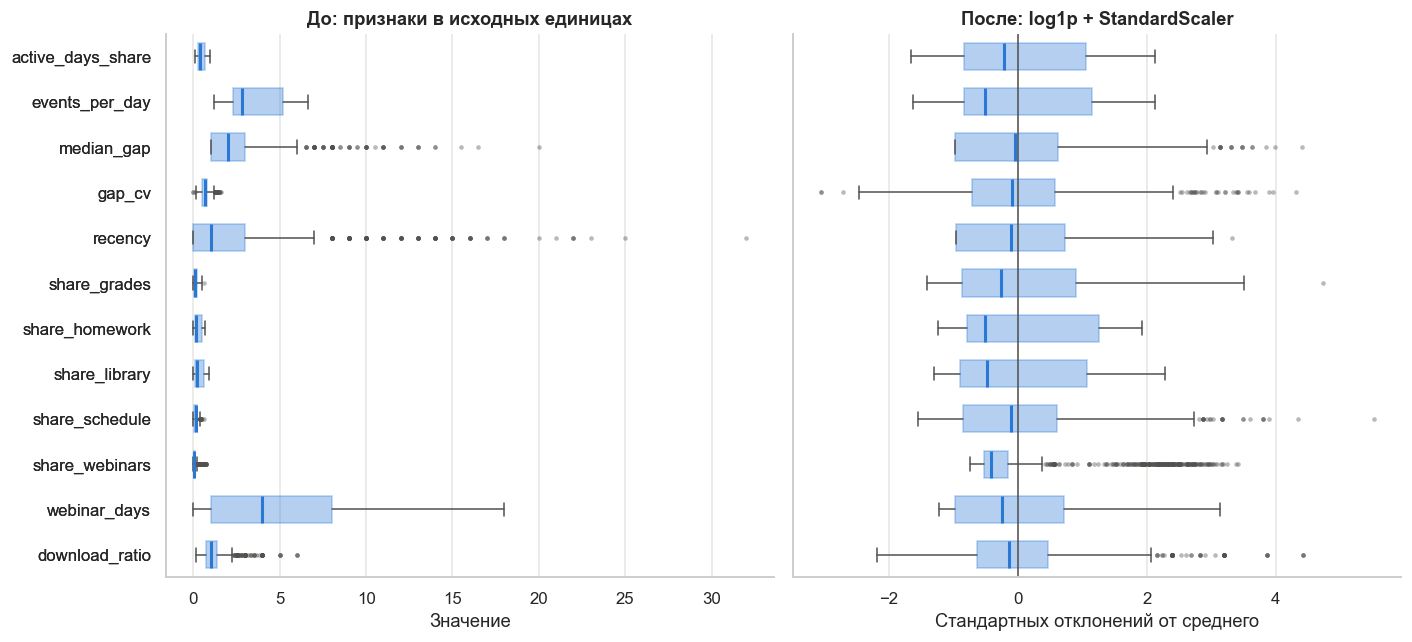

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
box_style = dict(vert=False, widths=0.6, patch_artist=True, showfliers=True,
                 boxprops=dict(facecolor=TEACHER_COLOR, edgecolor=TEACHER_COLOR, alpha=0.35),
                 medianprops=dict(color=TEACHER_COLOR, linewidth=2),
                 whiskerprops=dict(color='#52514e'), capprops=dict(color='#52514e'),
                 flierprops=dict(marker='o', markersize=3, markerfacecolor='#52514e',
                                 markeredgecolor='none', alpha=0.4))

axes[0].boxplot([m[c] for c in features], tick_labels=features, **box_style)
axes[0].set_title('До: признаки в исходных единицах')
axes[0].set_xlabel('Значение')

axes[1].boxplot([X[c] for c in features], tick_labels=features, **box_style)
axes[1].axvline(0, color='#52514e', linewidth=1)
axes[1].set_title('После: log1p + StandardScaler')
axes[1].set_xlabel('Стандартных отклонений от среднего')

for ax in axes:
    ax.grid(axis='y', visible=False)
axes[0].invert_yaxis()  
plt.tight_layout()
plt.show()

## <a id="s10"></a>10. Кластеризация: K-Means и DBSCAN

Кластеризуем матрицу `X` (1 483 учителя × 12 признаков) двумя методами:
- **K-Means** делит всех учителей на `k` групп вокруг центров; число `k` задаём сами;
- **DBSCAN** ищет плотные группы, а учителей вне их помечает как шум; главный параметр - радиус соседства `eps`.

### 10.1. K-Means с разным числом кластеров

In [26]:
results = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    results.append({'k': k,
                    'инерция': round(km.inertia_),
                    'силуэт': round(silhouette_score(X, km.labels_), 3),
                    'размеры кластеров': sorted(np.bincount(km.labels_).tolist(), reverse=True)})
km_results = pd.DataFrame(results).set_index('k')
display(km_results)

kmeans = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X)
km_labels = pd.Series(kmeans.labels_, index=X.index, name='K-Means')

,инерция,силуэт,размеры кластеров
k,,,
2,10441,0.421,"[1034, 449]"
3,7723,0.450,"[813, 449, 221]"
4,6046,0.447,"[539, 449, 279, 216]"
5,5665,0.441,"[531, 449, 216, 160, 127]"
6,5388,0.335,"[449, 336, 216, 208, 151, 123]"
7,5115,0.311,"[449, 331, 210, 154, 146, 124, 69]"
8,4877,0.313,"[449, 327, 206, 136, 109, 88, 88, 80]"
9,4661,0.187,"[329, 301, 207, 148, 147, 123, 85, 74, 69]"
10,4458,0.185,"[324, 281, 199, 168, 136, 87, 80, 75, 71, 62]"


При k = 2 модель отделяет только учителей, которые каждый день работают с ДЗ (449 человек), от всех остальных. С ростом k остальные делятся на более узкие группы. Начиная с k = 6 кластеры становятся мелкими, а силуэт падает. Оптимальный вариант - k = 4.

Даём кластерам названия, которые определяются **по профилю кластера, а не по номеру**:
- больше всех доля домашних заданий (`share_homework`) - «Ежедневные с ДЗ»;
- больше всех доля библиотеки (`share_library`) - «Библиотека»;
- больше всех доля вебинаров (`share_webinars`) - «Вебинары»;
- меньше всех доля активных дней (`active_days_share`) - «Редко заходящие».

In [27]:
km_medians = m[features].groupby(km_labels).median()
segment_names = {
    km_medians['share_homework'].idxmax(): 'Ежедневные с ДЗ',
    km_medians['share_library'].idxmax(): 'Библиотека',
    km_medians['share_webinars'].idxmax(): 'Вебинары',
    km_medians['active_days_share'].idxmin(): 'Редко заходящие',
}
assert len(segment_names) == 4, 'два правила указали на один кластер - проверьте профили'

SEGMENT_ORDER = ['Ежедневные с ДЗ', 'Библиотека', 'Вебинары', 'Редко заходящие']
km_segment = km_labels.map(segment_names).rename('сегмент K-Means')

display(pd.DataFrame({'номер кластера': {v: k for k, v in segment_names.items()},
                      'учителей': km_segment.value_counts()}).loc[SEGMENT_ORDER])

,номер кластера,учителей
Ежедневные с ДЗ,2,449
Библиотека,1,539
Вебинары,3,216
Редко заходящие,0,279


### 10.2. DBSCAN с разным `eps`

In [28]:
rows = []
for eps in [1.0, 1.5, 1.75, 2.0, 2.5]:
    labels = DBSCAN(eps=eps, min_samples=12).fit_predict(X)
    rows.append({'eps': eps,
                 'кластеров': len(set(labels)) - (-1 in labels),
                 'доля шума': f'{(labels == -1).mean():.0%}'})
display(pd.DataFrame(rows))

db_labels = pd.Series(DBSCAN(eps=1.75, min_samples=12).fit_predict(X), index=X.index, name='DBSCAN')

,eps,кластеров,доля шума
0,1.00,2,52%
1,1.50,3,24%
2,1.75,3,16%
3,2.00,3,9%
4,2.50,2,2%


`min_samples` = 12, по числу признаков.

При маленьком `eps` (1.0) плотными считаются только центры групп, и больше половины учителей уходит в шум. При большом (2.5) группы сливаются, и остаются 2 кластера. При `eps` от 1.5 до 2.0 результат стабилен: 3 кластера. Берём `eps = 1.75`: 3 кластера, 16% шума.

### 10.3. Сравнение K-Means и DBSCAN

In [29]:
# кластер DBSCAN называем по сегменту K-Means, с которым у него больше всего общих учителей
core = db_labels != -1
db_to_segment = pd.crosstab(db_labels[core], km_segment[core]).idxmax(axis=1)
db_segment = db_labels.map(db_to_segment).fillna('Шум').rename('сегмент DBSCAN')

display(pd.crosstab(km_segment, db_segment, margins=True, margins_name='всего')
          .reindex(index=SEGMENT_ORDER + ['всего'],
                   columns=[s for s in SEGMENT_ORDER if s in set(db_segment)] + ['Шум', 'всего']))

сегмент DBSCAN,Ежедневные с ДЗ,Библиотека,Вебинары,Шум,всего
сегмент K-Means,,,,,
Ежедневные с ДЗ,449,0,0,0,449
Библиотека,0,531,0,8,539
Вебинары,0,0,188,28,216
Редко заходящие,0,82,0,197,279
всего,449,613,188,233,1483


Строки - сегменты K-Means, столбцы - кластеры DBSCAN. Кластер DBSCAN назван по сегменту K-Means, с которым у него больше всего общих учителей; «Шум» - учителя, которых DBSCAN не отнёс ни к одной группе.

**Вывод:**
- **Три группы оба метода находят одинаково**: «Ежедневные с ДЗ» (449 учителей) совпали полностью, из 539 учителей «Библиотеки» в тот же кластер DBSCAN попали 531, из 216 «Вебинаров» - 188. Значит, эти сегменты устойчивые, а не случайность алгоритма.
- **Различие одно - «Редко заходящие» (279 учителей).** DBSCAN почти всех из них (197) считает шумом, а остальных присоединяет к «Библиотеке». У этих учителей нет плотного ядра: они заходят редко и ведут себя по-разному.
- **Основная модель - K-Means с k = 4**: он относит к сегменту каждого учителя, а для персонализации кабинета и рассылок это необходимо. DBSCAN подтверждает, что три основных сегмента устойчивы.

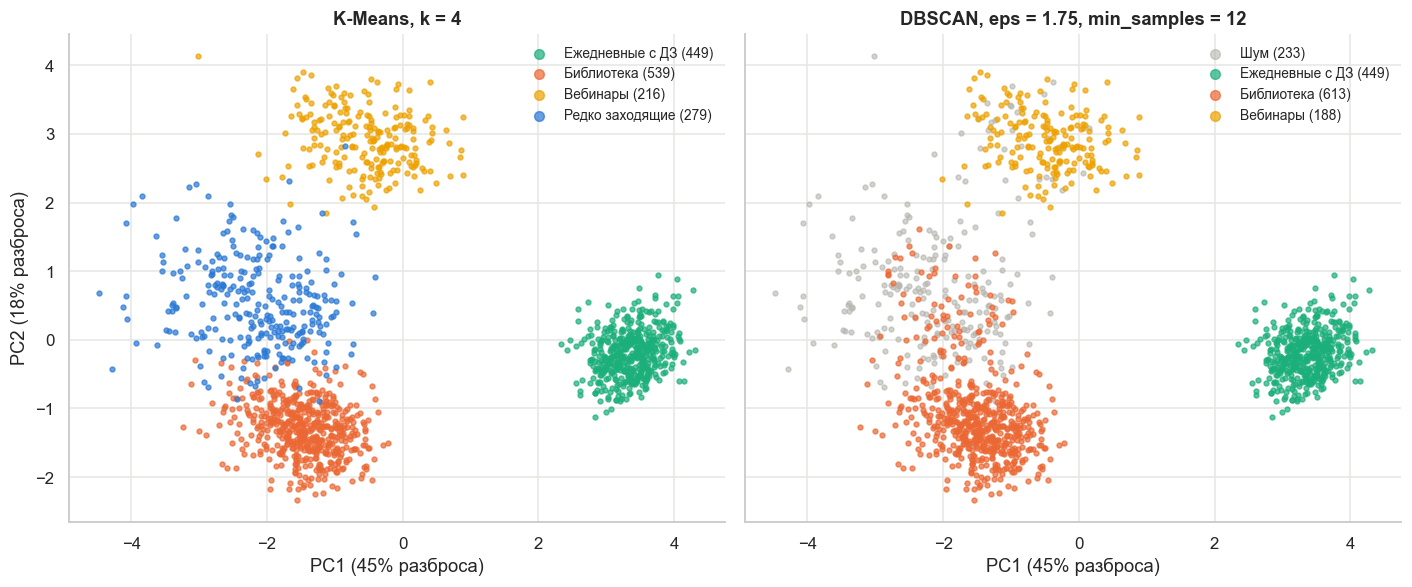

In [30]:
SEGMENT_COLORS = {'Ежедневные с ДЗ': '#1baf7a', 'Библиотека': '#eb6834',
                  'Вебинары': '#eda100', 'Редко заходящие': '#2a78d6'}
NOISE_COLOR = '#b5b4ae'

pca = PCA(n_components=2, random_state=42)
pc = pd.DataFrame(pca.fit_transform(X), index=X.index, columns=['PC1', 'PC2'])
var = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)

for seg in SEGMENT_ORDER:
    pts = pc[km_segment == seg]
    axes[0].scatter(pts['PC1'], pts['PC2'], s=10, alpha=0.7, color=SEGMENT_COLORS[seg],
                    label=f'{seg} ({len(pts)})')
axes[0].set_title('K-Means, k = 4')

pts = pc[db_segment == 'Шум']
axes[1].scatter(pts['PC1'], pts['PC2'], s=10, alpha=0.6, color=NOISE_COLOR, label=f'Шум ({len(pts)})')
for seg in SEGMENT_ORDER:
    pts = pc[db_segment == seg]
    if len(pts):
        axes[1].scatter(pts['PC1'], pts['PC2'], s=10, alpha=0.7, color=SEGMENT_COLORS[seg],
                        label=f'{seg} ({len(pts)})')
axes[1].set_title('DBSCAN, eps = 1.75, min_samples = 12')

for ax in axes:
    ax.set_xlabel(f'PC1 ({var[0]:.0%} разброса)')
    ax.legend(frameon=False, fontsize=9, markerscale=2)
axes[0].set_ylabel(f'PC2 ({var[1]:.0%} разброса)')
plt.tight_layout()
plt.show()

12 признаков на плоскости не нарисовать, поэтому учителей сжимаем до двух осей методом главных компонент (PCA). Эти две оси сохраняют около 62% разброса данных, поэтому часть точек на рисунке перекрывается, хотя в 12 признаках группы разделены лучше. Цвет обозначает сегмент: у обоих методов один и тот же сегмент одного цвета, серым показан шум DBSCAN.

На рисунке видно: «ежедневные с ДЗ» (зелёные) стоят отдельно от всех, «библиотека» (оранжевые) и «вебинары» (жёлтые) - две отдельные группы. «Редко заходящие» (синие) лежат разреженно между ними, и у DBSCAN именно они становятся шумом.

## <a id="s11"></a>11. Оценка качества кластеризации

### 11.1. Метод локтя и силуэтный коэффициент

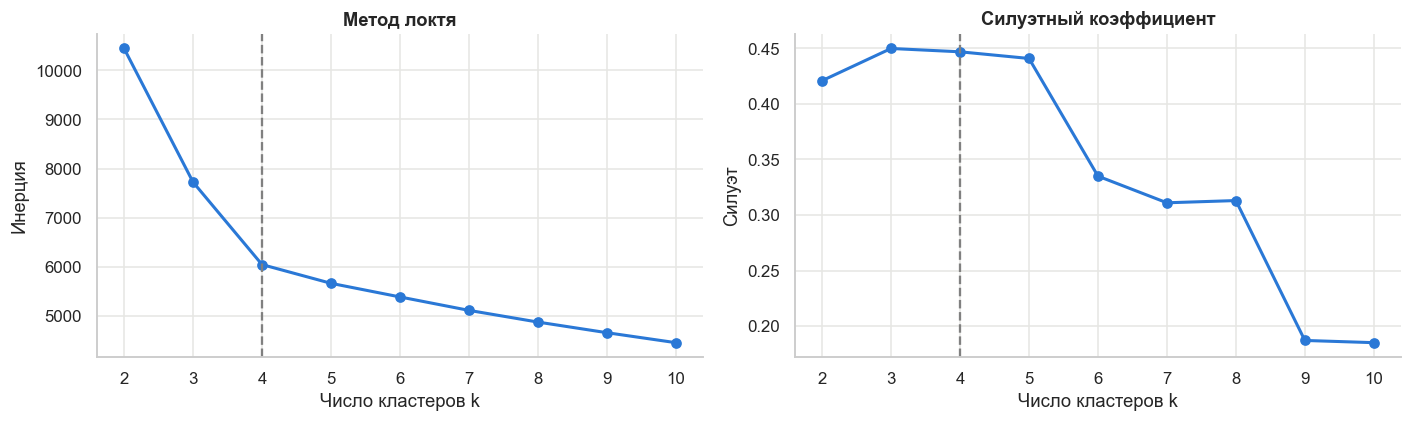

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(km_results.index, km_results['инерция'], marker='o', linewidth=2, color=TEACHER_COLOR)
axes[0].set_title('Метод локтя')
axes[0].set_ylabel('Инерция')

axes[1].plot(km_results.index, km_results['силуэт'], marker='o', linewidth=2, color=TEACHER_COLOR)
axes[1].set_title('Силуэтный коэффициент')
axes[1].set_ylabel('Силуэт')

for ax in axes:
    ax.axvline(4, color='grey', linestyle='--')
    ax.set_xlabel('Число кластеров k')
    ax.set_xticks(km_results.index)
plt.tight_layout()
plt.show()

**Инерция** - сумма квадратов расстояний от учителей до центров их кластеров: чем меньше, тем плотнее кластеры. Она всегда падает с ростом k, поэтому ищем «локоть», после которого падение замедляется.

**Силуэт** (от -1 до 1) показывает, насколько учитель ближе к своему кластеру, чем к соседнему: чем больше, тем лучше разделены группы.

**Вывод:**
- **Локоть на k = 4**: до него инерция падает резко (10 441 → 6 046), дальше медленно.
- **Силуэт максимальный при k = 3 и k = 4** (0.450 и 0.447), с k = 6 падает до 0.34. Значения около 0.45 говорят о хорошо различимых группах.
- Оба метода указывают на 3-4 кластера. Между ними выбираем по интерпретируемости.

### 11.2. Интерпретируемость кластеров

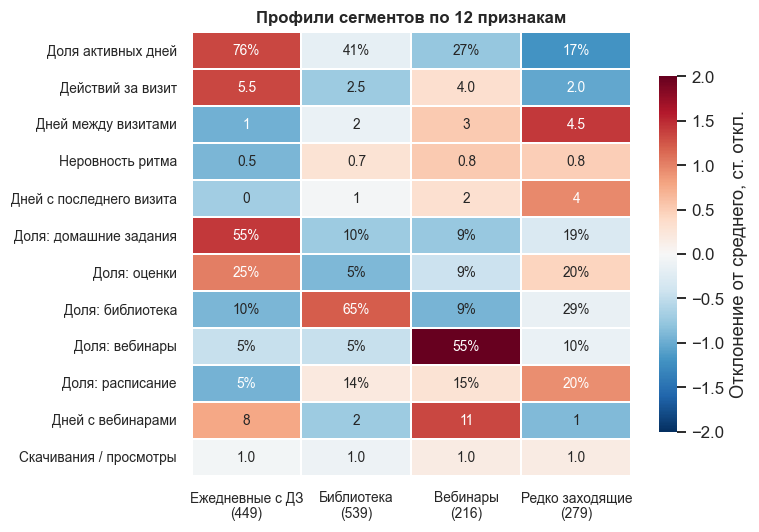

In [32]:
FEATURE_LABELS = {
    'active_days_share': 'Доля активных дней',
    'events_per_day': 'Действий за визит',
    'median_gap': 'Дней между визитами',
    'gap_cv': 'Неровность ритма',
    'recency': 'Дней с последнего визита',
    'share_homework': 'Доля: домашние задания',
    'share_grades': 'Доля: оценки',
    'share_library': 'Доля: библиотека',
    'share_webinars': 'Доля: вебинары',
    'share_schedule': 'Доля: расписание',
    'webinar_days': 'Дней с вебинарами',
    'download_ratio': 'Скачивания / просмотры',
}
order = list(FEATURE_LABELS)

z = X.groupby(km_segment).mean().T.loc[order, SEGMENT_ORDER]
med = m[features].groupby(km_segment).median().T.loc[order, SEGMENT_ORDER]

def fmt(feature, value):
    if feature == 'active_days_share' or feature.startswith('share_'):
        return f'{value:.0%}'
    if feature in ('events_per_day', 'gap_cv', 'download_ratio'):
        return f'{value:.1f}'
    return f'{value:g}'

labels = np.array([[fmt(f, med.loc[f, s]) for s in SEGMENT_ORDER] for f in order])

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(z, annot=labels, fmt='', cmap='RdBu_r', center=0, vmin=-2, vmax=2,
            linewidths=1, linecolor='white', annot_kws={'size': 9},
            cbar_kws={'label': 'Отклонение от среднего, ст. откл.', 'shrink': 0.8}, ax=ax)
ax.set_yticklabels([FEATURE_LABELS[f] for f in order], rotation=0, fontsize=9)
ax.set_xticklabels([f'{s}\n({(km_segment == s).sum()})' for s in SEGMENT_ORDER], rotation=0, fontsize=9)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('Профили сегментов по 12 признакам', fontsize=11)
plt.tight_layout()
plt.show()

В клетках - медианы признака в сегменте в исходных единицах (доли в процентах, интервалы и давность - в днях). Цвет - насколько сегмент отличается от среднего по всем учителям: красный - выше среднего, синий - ниже, белый - как у всех (по стандартизированным признакам, на которых обучалась модель). 

На карте видно, чем выделяется каждый сегмент:
- **Ежедневные с ДЗ** - выше всех по частоте, действиям за визит, доле ДЗ и оценок; ниже всех по интервалам между визитами и давности последнего визита;
- **Библиотека** - выделяется долей библиотеки; ниже среднего по ДЗ, оценкам, вебинарам и действиям за визит;
- **Вебинары** - выделяются долей вебинаров и числом дней с вебинарами; заходят реже среднего;
- **Редко заходящие** - выше всех по интервалам между визитами и давности последнего визита, ниже всех по частоте и действиям за визит; чаще других смотрят расписание, а ни один рабочий модуль (ДЗ, библиотека, вебинары) не выделяется - «своего» сценария нет.

«Скачивания / просмотры» почти одинаковы во всех сегментах: этот признак сегменты не различает.

По сравнению с k = 3 вариант k = 4 выделяет в отдельную группу редко заходящих учителей. Для продукта это важный сегмент: риск оттока. При k = 3 они смешаны с «библиотекой».

**Итог: k = 4.** Его подтверждают все три критерия: локоть на 4, силуэт близок к максимальному (0.447), и четыре группы хорошо различаются и понятны на языке продукта.

## <a id="s12"></a>12. Портреты сегментов
**5 сегментов**: 4 из кластеризации K-Means и «Спящие» - 17 учителей с очень малой активностью.

### 12.1. Ключевые продуктовые метрики сегментов

In [33]:
SEGMENTS = SEGMENT_ORDER + ['Спящие']
SEGMENT_COLORS['Спящие'] = '#8f8e88'

segment = pd.Series('Спящие', index=teachers.index, name='сегмент')
segment.loc[km_segment.index] = km_segment

seg_df = teachers.join(segment)
seg_df['recency'] = (period_end - seg_df['last_seen'].dt.normalize()).dt.days
seg_df['active_days_30'] = seg_df['active_days'] / seg_df['days_in_log'] * 30
seg_df['events_per_day'] = seg_df['events'] / seg_df['active_days']

g = seg_df.groupby('сегмент')
portrait = pd.DataFrame({
    'учителей': g.size(),
    'доля учителей': g.size() / len(seg_df),
    'активных дней в месяц': g['active_days_30'].median(),
    'действий за визит': g['events_per_day'].median(),
    'дней с последнего визита': g['recency'].median(),
    'заходили за последние 7 дней': g['recency'].apply(lambda s: (s <= 6).mean()),
    'доля всех действий на платформе': g['events'].sum() / seg_df['events'].sum(),
}).loc[SEGMENTS]

display(portrait.style.format({
    'учителей': '{:.0f}', 'доля учителей': '{:.0%}', 'активных дней в месяц': '{:.1f}',
    'действий за визит': '{:.1f}', 'дней с последнего визита': '{:.0f}',
    'заходили за последние 7 дней': '{:.0%}', 'доля всех действий на платформе': '{:.1%}',
}))

,учителей,доля учителей,активных дней в месяц,действий за визит,дней с последнего визита,заходили за последние 7 дней,доля всех действий на платформе
сегмент,,,,,,,
Ежедневные с ДЗ,449,30%,22.7,5.5,0,100%,68.8%
Библиотека,539,36%,12.3,2.5,1,96%,19.6%
Вебинары,216,14%,8.2,4.0,2,89%,8.3%
Редко заходящие,279,19%,5.0,2.0,4,67%,3.3%
Спящие,17,1%,2.2,2.0,8,47%,0.1%


- **активных дней в месяц** - сколько дней из 30 учитель заходит на платформу (медиана по сегменту), связано с продуктовой метрикой «активные дни в месяц»;
- **заходили за последние 7 дней** и **дней с последнего визита** - показатели удержания;
- **доля всех действий на платформе** - какой вклад сегмент вносит в общую активность.

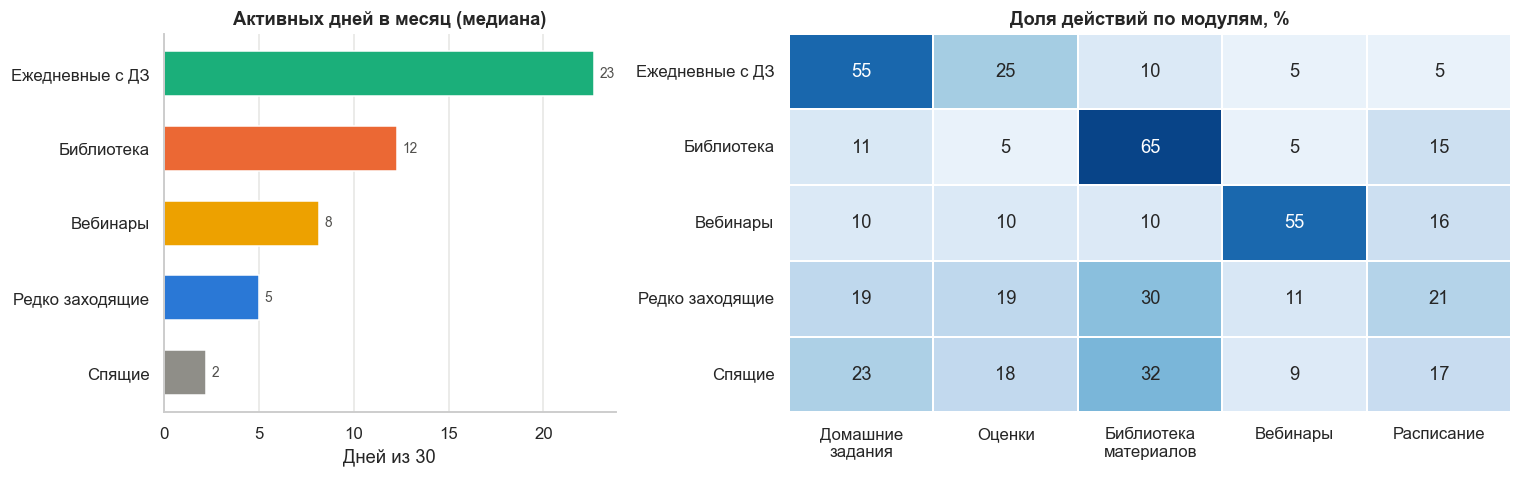

In [34]:
MODULE_ORDER = ['Домашние задания', 'Оценки', 'Библиотека материалов', 'Вебинары', 'Расписание']
module_share = pd.crosstab(df['user_id'].map(segment), df['module'], normalize='index').loc[SEGMENTS, MODULE_ORDER] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})

vals = portrait['активных дней в месяц']
axes[0].barh(SEGMENTS, vals, color=[SEGMENT_COLORS[s] for s in SEGMENTS], height=0.6)
for y, v in enumerate(vals):
    axes[0].text(v + 0.3, y, f'{v:.0f}', va='center', fontsize=9, color='#52514e')
axes[0].invert_yaxis()
axes[0].set_title('Активных дней в месяц (медиана)')
axes[0].set_xlabel('Дней из 30')
axes[0].grid(axis='y', visible=False)

sns.heatmap(module_share, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=70, cbar=False,
            linewidths=1, linecolor='white', ax=axes[1])
axes[1].set_title('Доля действий по модулям, %')
axes[1].set_xlabel('')
axes[1].set_ylabel('')
axes[1].set_xticklabels([name.replace(' ', '\n') for name in MODULE_ORDER], rotation=0)

plt.tight_layout()
plt.show()

In [35]:
region_ct = pd.crosstab(segment, df.groupby('user_id')['region'].first())
p_value = stats.chi2_contingency(region_ct)[1]
print(f'Связь сегмента с регионом (критерий хи-квадрат): p = {p_value:.2f}')

Связь сегмента с регионом (критерий хи-квадрат): p = 0.39


**Вывод:**
- Сегменты сильно различаются по частоте: от 23 активных дней в месяц у «Ежедневных с ДЗ» до 5 у «Редко заходящих» и 2 у «Спящих».
- Каждый из трёх активных сегментов держится на «своём» модуле: ДЗ и оценки, библиотека или вебинары. Остальные модули у них занимают по 5-15%.
- «Ежедневные с ДЗ» - 30% учителей, но 69% всех действий на платформе.
- Сегмент не зависит от региона (p = 0.39 > 0.05): учителей разделяет поведение, а не география, поэтому подход к сегментам можно делать единым для всех регионов.

### 12.2. Продуктовые портреты

**1. «Ежедневные с ДЗ» - 449 учителей (30%)**<br>
*Платформа - основной рабочий инструмент.*
- **Как пользуются:** заходят почти каждый день (23 активных дня в месяц), за визит около 5-6 действий. Больше половины действий - выдача и проверка домашних заданий, четверть - выставление и просмотр оценок. Библиотекой пользуются мало (10%), вебинарами и расписанием - почти нет (по 5%).
- **Вовлечённость:** все заходили за последнюю неделю; дают 69% всех действий на платформе.
- **Что для них главное:** быстрый ежедневный цикл «выдать ДЗ - проверить - поставить оценку».
- **Особенность:** самые лояльные пользователи, но используют узкий сценарий: библиотека и вебинары им почти незнакомы.

**2. «Библиотека» - 539 учителей (36%), самый большой сегмент**<br>
*Платформа - цифровая библиотека для подготовки к очным урокам.*
- **Как пользуются:** около 12 активных дней в месяц, визиты короткие (2-3 действия): зашёл, нашёл материал, ушёл. Две трети действий - библиотека материалов (просмотр и скачивание поровну), ещё 15% - расписание.
- **Вовлечённость:** 96% заходили за последнюю неделю; 20% всех действий.
- **Что для них главное:** быстро найти подходящий материал к уроку.
- **Особенность:** домашние задания и оценки почти не используют (11% и 5%) - уроки ведут очно, а платформа нужна только для подготовки.

**3. «Вебинары» - 216 учителей (14%)**<br>
*Платформа - инструмент онлайн-занятий.*
- **Как пользуются:** около 8 активных дней в месяц, но визиты насыщенные (4 действия): в день вебинара учитель запускает и проводит трансляцию. Больше половины действий - вебинары, 16% - расписание; остальные модули по ~10%.
- **Вовлечённость:** 89% заходили за последнюю неделю; 8% всех действий.
- **Что для них главное:** стабильные трансляции и удобное планирование занятий.
- **Особенность:** заходят «по расписанию вебинаров», между занятиями платформой почти не пользуются.

**4. «Редко заходящие» - 279 учителей (19%)**<br>
*Платформа - эпизодический инструмент, привычки пользоваться нет.*
- **Как пользуются:** около 5 активных дней в месяц, 2 действия за визит, между визитами 4-5 дней. Используют всё понемногу (библиотека 30%, расписание 21%, ДЗ и оценки по 19%) - «своего» сценария не нашли.
- **Вовлечённость:** только 67% заходили за последнюю неделю, медиана - 4 дня без визитов; 3% всех действий.
- **Что для них главное:** понять, чем платформа полезна именно им.
- **Особенность:** главная группа риска оттока. DBSCAN почти всех их относит к шуму: поведение внутри сегмента разнородное, причины редкого использования могут быть разными.

**5. «Спящие» - 17 учителей (1%)**<br>
*Платформой фактически не пользуются.*
- **Как пользуются:** меньше 5 действий или меньше 3 активных дней за весь период - около 2 дней в месяц.
- **Вовлечённость:** меньше половины (47%) заходили за последнюю неделю, медиана - 8 дней без визитов. 3 из 17 - новички, пришедшие в последние две недели.
- **Что для них главное:** разобраться, как начать работу с платформой.
- **Особенность:** либо ещё не начали пользоваться (новички), либо уже ушли.

### 12.3. Итог

| Сегмент | Учителей | Активных дней в месяц | Главный модуль | Роль платформы | Ключевой риск |
|---|---|---|---|---|---|
| Ежедневные с ДЗ | 449 (30%) | 23 | ДЗ и оценки | основной рабочий инструмент | узкий сценарий |
| Библиотека | 539 (36%) | 12 | библиотека материалов | подготовка к очным урокам | короткие визиты, ДЗ не используют |
| Вебинары | 216 (14%) | 8 | вебинары | онлайн-занятия | заходят только в дни вебинаров |
| Редко заходящие | 279 (19%) | 5 | нет «своего» | эпизодический инструмент | отток |
| Спящие | 17 (1%) | 2 | нет | не используется | уже ушли или не начали |

## <a id="s13"></a>13. Бизнес-рекомендации

Для каждого сегмента: цель, как адаптировать **личный кабинет**, какие нужны **коммуникации** и **сценарии взаимодействия**, по какой метрике проверять результат.

### 13.1. «Ежедневные с ДЗ» - 449 учителей (30%)

**Цель:** удержать самый ценный сегмент (69% всех действий) и расширить его сценарий за пределы ДЗ и оценок.

- **Личный кабинет:** главный экран - рабочий стол на сегодня: «ДЗ на проверку», «сдали / не сдали», быстрые кнопки «выдать ДЗ» и «выставить оценки». Массовая проверка и шаблоны ДЗ. В форме создания ДЗ - блок «материалы библиотеки к этой теме».
- **Коммуникации:** только полезные уведомления (новые сданные работы, дедлайны), без маркетинговых рассылок - эти учителя и так заходят каждый день. Ежемесячный отчёт об успеваемости классов. Приглашения в бета-тест новых функций ДЗ.
- **Сценарии:** «прикрепить материал из библиотеки к ДЗ» и «провести вебинар-консультацию перед контрольной» - знакомство с модулями, которыми они почти не пользуются (библиотека 10%, вебинары 5%).
- **Метрика:** удержание (сейчас 100% заходили за неделю - не потерять), доля учителей, использующих библиотеку в ДЗ.

### 13.2. «Библиотека» - 539 учителей (36%)

**Цель:** самый большой сегмент - увеличить частоту визитов и перевести часть учителей к выдаче ДЗ через платформу.

- **Личный кабинет:** главный экран - поиск и подборки материалов по предмету и классу, «к вашим урокам на этой неделе» (по расписанию), избранное и история скачиваний. На карточке материала - кнопка «выдать как ДЗ».
- **Коммуникации:** еженедельный дайджест новых материалов по предмету в воскресенье вечером, перед учебной неделей. Тематические подборки к контрольным и концу четверти.
- **Сценарии:** «материал → ДЗ в один клик» - самый короткий путь от привычного действия к новому модулю. Блок «похожие материалы» и «что берут коллеги по предмету».
- **Метрика:** активные дни в месяц (сейчас 12), доля учителей, выдавших хотя бы одно ДЗ из материала.

### 13.3. «Вебинары» - 216 учителей (14%)

**Цель:** чтобы учитель заходил не только в дни вебинаров (сейчас 8 активных дней в месяц).

- **Личный кабинет:** главный экран - ближайшие трансляции и кнопка «начать вебинар», проверка камеры и микрофона, записи прошедших вебинаров со статистикой посещаемости.
- **Коммуникации:** напоминания за день и за час до вебинара; после вебинара - отчёт (кто был, ссылка на запись). Советы по интерактиву: опросы, доска, работа в группах.
- **Сценарии:** после завершения трансляции - предложение «выдать ДЗ по итогам вебинара»; запись вебинара сохраняется в библиотеку; материалы библиотеки можно показать прямо на вебинаре.
- **Метрика:** активные дни в месяц, доля вебинаров с ДЗ по итогам.

### 13.4. «Редко заходящие» - 279 учителей (19%)

**Цель:** главный риск оттока - вернуть регулярность и помочь найти «свой» сценарий.

- **Личный кабинет:** упрощённый главный экран с выбором из трёх сценариев: «выдать ДЗ», «найти материал к уроку», «провести урок онлайн». Персональная подсказка по тому, чем учитель уже пользовался.
- **Коммуникации:** триггер реактивации - если учитель не заходил 5 дней (их обычный интервал 4-5 дней), письмо или пуш с конкретной пользой: новые материалы по его предмету, «ученики сдали ДЗ». Короткий опрос «что мешает пользоваться платформой»: поведение в сегменте разнородное (DBSCAN почти всех отнёс к шуму), поэтому причины нужно узнать, а не угадывать.
- **Сценарии:** онбординг-марафон «7 дней с платформой» - каждый день одно короткое задание из разных модулей. Обучающий вебинар для новых пользователей.
- **Метрика:** доля заходивших за последние 7 дней (сейчас 67%), переход учителей в активные сегменты.

### 13.5. «Спящие» - 17 учителей (1%)

**Цель:** активация - либо начать пользоваться, либо понять, почему ушли.

- **Личный кабинет:** мастер первой настройки (предмет, классы) и чек-лист первых шагов.
- **Коммуникации:** приветственная серия писем для новичков (3 из 17 пришли в последние две недели); одно письмо «мы скучаем» для ушедших, без частых рассылок.
- **Сценарии:** сегмент маленький, поэтому возможен личный контакт поддержки - звонок или письмо с вопросом о трудностях.
- **Метрика:** активация - 3 и больше активных дня за первые две недели.

### 13.6. Приоритеты и внедрение

| Приоритет | Сегмент | Почему | Главное действие |
|---|---|---|---|
| 1 | Редко заходящие | 19% учителей под риском оттока | триггер реактивации + опрос о причинах |
| 2 | Библиотека | самый большой сегмент, частота всего 12 дней в месяц | «материал → ДЗ в один клик», еженедельный дайджест |
| 3 | Вебинары | заходят только в дни трансляций | ДЗ по итогам вебинара, запись в библиотеку |
| 4 | Ежедневные с ДЗ | ядро платформы, 69% действий | удобный рабочий стол, без лишних рассылок |
| 5 | Спящие | 17 человек | личный контакт и онбординг |

**Как внедрять и проверять:**
- каждую рекомендацию запускать как **A/B-тест** внутри сегмента и сравнивать метрику сегмента с контрольной группой;
- **пересчитывать сегменты раз в месяц**: новых учителей относить к сегменту той же моделью (те же 12 признаков, `log1p`, тот же `scaler` и `kmeans.predict`), а переходы между сегментами отслеживать как отдельную метрику;
- ограничение: данные за 45 дней, сезонность (каникулы, конец четверти) в них не видна - сегменты стоит перепроверить на более длинном периоде.

### 13.7. Выгрузка сегментов для CRM и рассылок

In [36]:
segments_export = seg_df[['сегмент', 'active_days', 'events', 'recency']].rename(columns={
    'сегмент': 'segment', 'recency': 'days_since_last_visit'})
segments_export['region'] = df.groupby('user_id')['region'].first()
segments_export.to_csv('data/teacher_segments.csv', encoding='utf-8-sig')
print(f'Сохранено: data/teacher_segments.csv, {len(segments_export)} учителей')
display(segments_export['segment'].value_counts().reindex(SEGMENTS).rename('учителей').to_frame())

Сохранено: data/teacher_segments.csv, 1500 учителей


,учителей
segment,
Ежедневные с ДЗ,449
Библиотека,539
Вебинары,216
Редко заходящие,279
Спящие,17


Файл `data/teacher_segments.csv` - сегмент каждого учителя; по нему можно настроить персональный кабинет и таргетированные рассылки.

## <a id="s14"></a>14. Дополнительно: классификатор и RFM-анализ

### 14.1. Классификатор: к какому сегменту отнести нового учителя

Кластеризацию не нужно перезапускать для каждого нового учителя: достаточно классификатора, который по метрикам учителя сразу называет сегмент.

- **Модель - дерево решений.** Его можно записать в виде понятных правил «если ... то сегмент ...», которые продуктовая команда может проверить сама.
- **Признаки** - те же 12 метрик в исходных единицах (дни, доли): дереву не нужна стандартизация, поэтому правила получаются в понятных величинах.
- **Ответ** - сегмент K-Means.
- **Проверка** - 25% учителей откладываем как тестовую выборку (с сохранением долей сегментов), плюс кросс-валидация на 5 частях.

In [37]:
X_tree = m[features]
y_tree = km_segment
X_train, X_test, y_train, y_test = train_test_split(
    X_tree, y_tree, test_size=0.25, stratify=y_tree, random_state=42)

depth_rows = []
for depth in [2, 3, 4, None]:
    tree_d = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    cv = cross_val_score(DecisionTreeClassifier(max_depth=depth, random_state=42), X_tree, y_tree, cv=5)
    depth_rows.append({'глубина': 'без ограничения' if depth is None else depth,
                       'правил (листьев)': tree_d.get_n_leaves(),
                       'точность на тесте': accuracy_score(y_test, tree_d.predict(X_test)),
                       'точность, кросс-валидация': cv.mean()})
display(pd.DataFrame(depth_rows).set_index('глубина').style.format(
    {'точность на тесте': '{:.1%}', 'точность, кросс-валидация': '{:.1%}'}))

,правил (листьев),точность на тесте,"точность, кросс-валидация"
глубина,,,
2,4,82.2%,82.8%
3,6,96.8%,97.5%
4,9,97.8%,98.0%
без ограничения,26,97.3%,97.7%


In [38]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
print(f'Точность на тестовой выборке: {accuracy_score(y_test, tree.predict(X_test)):.1%}')

confusion = pd.crosstab(y_test.rename('сегмент K-Means'), pd.Series(tree.predict(X_test), index=y_test.index, name='прогноз дерева'))
display(confusion.reindex(index=SEGMENT_ORDER, columns=SEGMENT_ORDER, fill_value=0))

print('Правила дерева:')
print(export_text(tree, feature_names=[FEATURE_LABELS[f] for f in features], decimals=2))

Точность на тестовой выборке: 96.8%


прогноз дерева,Ежедневные с ДЗ,Библиотека,Вебинары,Редко заходящие
сегмент K-Means,,,,
Ежедневные с ДЗ,112,0,0,0
Библиотека,0,127,0,8
Вебинары,0,0,54,0
Редко заходящие,0,2,2,66


Правила дерева:
|--- Доля активных дней <= 0.58
|   |--- Доля: библиотека <= 0.50
|   |   |--- Действий за визит <= 3.13
|   |   |   |--- class: Редко заходящие
|   |   |--- Действий за визит >  3.13
|   |   |   |--- class: Вебинары
|   |--- Доля: библиотека >  0.50
|   |   |--- Дней между визитами <= 4.75
|   |   |   |--- class: Библиотека
|   |   |--- Дней между визитами >  4.75
|   |   |   |--- class: Редко заходящие
|--- Доля активных дней >  0.58
|   |--- Доля: библиотека <= 0.47
|   |   |--- class: Ежедневные с ДЗ
|   |--- Доля: библиотека >  0.47
|   |   |--- class: Библиотека



In [39]:
def assign_segment(metrics, info):
    """Сегмент для учителей: metrics - 12 метрик (как в m), info - строки таблицы teachers."""
    result = pd.Series(tree.predict(metrics[features]), index=metrics.index, name='сегмент')
    sleeping = (info['events'] < 5) | (info['active_days'] < 3)
    newcomer = info['days_in_log'] < 14
    result[newcomer.reindex(result.index)] = 'Новичок: мало данных'
    result[sleeping.reindex(result.index)] = 'Спящие'
    return result

demo = assign_segment(X_test, teachers.loc[X_test.index])
print(f'Совпадает с сегментом K-Means: {(demo == y_test).mean():.1%}')
display(pd.concat([y_test.rename('сегмент K-Means'), demo.rename('классификатор')], axis=1).head(8))

Совпадает с сегментом K-Means: 96.8%


,сегмент K-Means,классификатор
user_id,,
T101273,Библиотека,Библиотека
T100451,Редко заходящие,Редко заходящие
T101166,Редко заходящие,Редко заходящие
T100201,Редко заходящие,Редко заходящие
T100413,Редко заходящие,Редко заходящие
T100877,Библиотека,Библиотека
T101192,Редко заходящие,Редко заходящие
T100480,Библиотека,Библиотека


**Вывод по классификатору:**
- **Глубина 3** - компромисс между точностью и понятностью: 6 правил, 96.8% на тесте и 97.5% на кросс-валидации. Глубина 4 добавляет около 1 п.п., но правил уже 9; дерево без ограничения - 26 правил и точность не выше.
- **Ошибки только на границах соседних сегментов:** 8 учителей «Библиотеки» отнесены к «Редко заходящим», 4 «Редко заходящих» - к «Библиотеке» и «Вебинарам». «Ежедневные с ДЗ» и «Вебинары» распознаны без ошибок.
- **Правила на языке продукта:**
  1. Заходит больше чем в 58% дней: библиотека не больше 47% действий - «Ежедневные с ДЗ», больше - «Библиотека».
  2. Заходит реже, библиотека больше 50% действий: между визитами до 4.75 дня - «Библиотека», дольше - «Редко заходящие».
  3. Заходит реже, библиотека не больше 50%: больше 3.1 действия за визит - «Вебинары», меньше - «Редко заходящие».
- Дереву хватило трёх главных признаков: доли активных дней, доли библиотеки и действий за визит. «Вебинары» оно отличает не по доле вебинаров, а по насыщенным визитам: среди нечастых учителей без библиотеки много действий за визит бывает у тех, кто проводит трансляции.
- Высокая точность ожидаема: дерево учится на тех же признаках, по которым строились сегменты. Его ценность - в понятных правилах. Функция `assign_segment` дополняет их бизнес-правилами: меньше 5 действий или меньше 3 активных дней - «Спящие», меньше 14 дней в логе - «Новичок: мало данных» (поведение ещё не сложилось).

### 14.2. RFM-анализ: лояльность и активность сегментов

RFM - классическая оценка клиента по трём показателям. Монетизации в логе нет, поэтому «M» - объём действий:
- **R (Recency)** - дней с последнего визита;
- **F (Frequency)** - активных дней в месяц;
- **M (Monetary)** - действий в месяц.

Каждому учителю ставим балл от 1 до 3 по каждому показателю (3 - лучше) и складываем баллы:

| Балл | R: дней с последнего визита | F: активных дней в месяц | M: действий в месяц |
|---|---|---|---|
| 3 | 0-1 | 15 и больше | 60 и больше |
| 2 | 2-4 | 8-14 | 25-59 |
| 1 | 5 и больше | меньше 8 | меньше 25 |

Сумма баллов (3-9) даёт RFM-группу: **8-9 - «Чемпионы»**, **6-7 - «Лояльные»**, **4-5 - «Нужно внимание»**, **3 - «Под угрозой ухода»**. Считаем для всех 1 500 учителей, включая «Спящих».

In [40]:
rfm = seg_df[['сегмент', 'recency', 'active_days_30']].copy()
rfm['events_30'] = seg_df['events'] / seg_df['days_in_log'] * 30

rfm['R'] = np.select([rfm['recency'] <= 1, rfm['recency'] <= 4], [3, 2], default=1)
rfm['F'] = np.select([rfm['active_days_30'] >= 15, rfm['active_days_30'] >= 8], [3, 2], default=1)
rfm['M'] = np.select([rfm['events_30'] >= 60, rfm['events_30'] >= 25], [3, 2], default=1)
rfm['RFM'] = rfm['R'] + rfm['F'] + rfm['M']

RFM_GROUPS = ['Чемпионы', 'Лояльные', 'Нужно внимание', 'Под угрозой ухода']
rfm['RFM-группа'] = pd.cut(rfm['RFM'], bins=[2, 3, 5, 7, 9], labels=RFM_GROUPS[::-1])

print('Средние RFM-баллы по сегментам:')
rfm_by_segment = (rfm.groupby('сегмент')[['R', 'F', 'M', 'RFM']].mean().loc[SEGMENTS])
display(rfm_by_segment.style.format('{:.1f}'))

Средние RFM-баллы по сегментам:


,R,F,M,RFM
сегмент,,,,
Ежедневные с ДЗ,2.9,3.0,3.0,8.9
Библиотека,2.5,2.1,1.8,6.4
Вебинары,2.2,1.6,1.9,5.6
Редко заходящие,1.8,1.1,1.0,3.8
Спящие,1.2,1.0,1.0,3.2


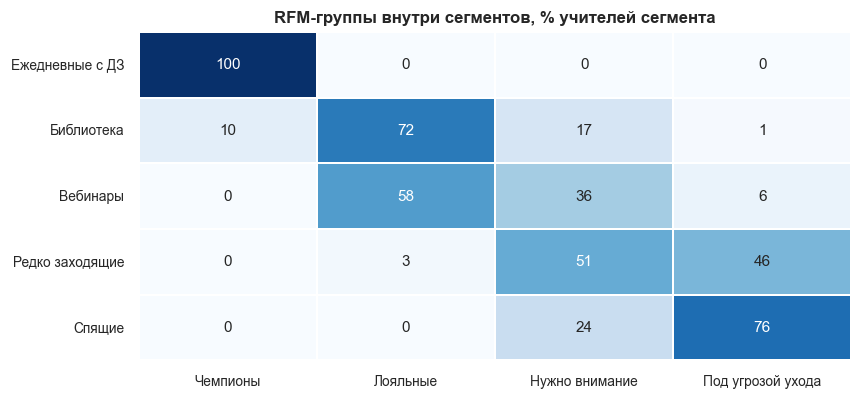

Учителей по RFM-группам:


RFM-группа,Чемпионы,Лояльные,Нужно внимание,Под угрозой ухода
учителей,501,519,316,164


In [41]:
rfm_share = pd.crosstab(rfm['сегмент'], rfm['RFM-группа'], normalize='index').reindex(
    index=SEGMENTS, columns=RFM_GROUPS, fill_value=0) * 100

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(rfm_share, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, cbar=False,
            linewidths=1, linecolor='white', annot_kws={'size': 10}, ax=ax)
ax.set_title('RFM-группы внутри сегментов, % учителей сегмента', fontsize=11)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

print('Учителей по RFM-группам:')
display(rfm['RFM-группа'].value_counts().reindex(RFM_GROUPS).rename('учителей').to_frame().T)

**Вывод по RFM:**
- RFM **подтверждает сегментацию**:
  - «Ежедневные с ДЗ» - 100% «Чемпионы» (средний балл 8.9 из 9);
  - «Библиотека» - в основном «Лояльные» (72%): заходят часто, но действий за месяц немного (M = 1.8);
  - «Вебинары» - «Лояльные» (58%) и «Нужно внимание» (36%): заходят реже других активных сегментов (F = 1.6);
  - «Редко заходящие» - «Нужно внимание» (51%) и «Под угрозой ухода» (46%);
  - «Спящие» - 76% «Под угрозой ухода».
- **164 учителя «Под угрозой ухода»**, около 80% из них - «Редко заходящие». С них стоит начинать реактивацию.

## <a id="s15"></a>15. Итоги

1. **Данные очищены:** удалены 15 ботов (94 283 события, 44% лога), 29 полных дубликатов и 50 почти-дублей; 7 102 пропуска в `module` восстановлены по `event_type`.
2. **Построена матрица** из 16 продуктовых метрик по 4 группам: частота, регулярность, структура использования, глубина работы с модулями. В модель вошли 12 признаков после удаления дублей, логарифмирования и стандартизации.
3. **Кластеризация:** K-Means с k = 4 - основная модель (локоть на 4, силуэт 0.447). DBSCAN независимо нашёл те же 3 ядровых сегмента и подтвердил их устойчивость.
4. **5 сегментов:**
   - «Ежедневные с ДЗ» (30%) - платформа как основной рабочий инструмент, 69% всех действий;
   - «Библиотека» (36%) - подготовка к очным урокам;
   - «Вебинары» (14%) - онлайн-занятия;
   - «Редко заходящие» (19%) - нет своего сценария, риск оттока;
   - «Спящие» (1%) - нужна активация.
5. **Рекомендации:** для каждого сегмента - свой главный экран личного кабинета, коммуникации и сценарии перехода к соседним модулям. Первые приоритеты - реактивация «Редко заходящих» и рост частоты в «Библиотеке».
6. **Дополнительно** (раздел 14): дерево решений относит новых учителей к сегментам с точностью около 97% по 6 понятным правилам; RFM-анализ независимо подтверждает сегментацию и выделяет 164 учителя под угрозой ухода.

### *Для дашборда

In [42]:
PBI_DIR = Path('power_bi')
PBI_DIR.mkdir(exist_ok=True)

# события
fact_events = pd.DataFrame({
    'user_id': df['user_id'],
    'date': df['timestamp'].dt.normalize(),
    'module': df['module'],
})

# учителя
dim_teacher = pd.DataFrame({
    'user_id': seg_df.index,
    'segment': seg_df['сегмент'].values,
    'active_days_per_month': seg_df['active_days_30'].round(1).values,
    'days_since_last_visit': seg_df['recency'].values,
    'rfm_group': rfm['RFM-группа'].reindex(seg_df.index).astype(str).values,
})

# сегменты
dim_segment = pd.DataFrame({
    'segment': SEGMENTS,
    'sort_order': range(1, len(SEGMENTS) + 1),
})

for name, table in [('fact_events', fact_events), ('dim_teacher', dim_teacher), ('dim_segment', dim_segment)]:
    table.to_csv(PBI_DIR / f'{name}.csv', index=False, encoding='utf-8-sig')
    print(f'{name}.csv: {len(table):,} строк, столбцы: {list(table.columns)}')

fact_events.csv: 120,597 строк, столбцы: ['user_id', 'date', 'module']
dim_teacher.csv: 1,500 строк, столбцы: ['user_id', 'segment', 'active_days_per_month', 'days_since_last_visit', 'rfm_group']
dim_segment.csv: 5 строк, столбцы: ['segment', 'sort_order']
